In [42]:
!pip install optuna


# Proyecto Final de Minería de Datos
## Notebook 02. Modelado predictivo (Credit Card Churn)

Partimos de los datos limpios del Notebook 01 para predecir qué clientes abandonan la tarjeta de crédito. Creamos nuevas variables, dividimos los datos en 70% de entrenamiento y 30% de prueba y balanceamos solo el entrenamiento con SMOTENC. Luego comparamos 4 métodos supervisados y 3 de ensamble con validación cruzada, escogemos los 3 mejores con ANOVA y Tukey, los optimizamos con GridSearchCV y Optuna, y guardamos el mejor en un Pipeline para el despliegue.

---
## 1. Carga de datos e ingeniería de características
Cargamos `credit_card_churn_limpio.csv` (10,120 registros y 19 columnas) y codificamos `Attrition_Flag` como 1 si el cliente abandona y 0 si se queda.

Creamos tres variables nuevas.
- `Avg_Ticket_Size`, el valor promedio por transacción.
- `Inactivity_Contact_Ratio`, meses inactivo por contactos con el banco, porque un cliente que no usa la tarjeta y llama mucho tiene más riesgo de irse.
- `Products_Per_Year`, productos por cada año en el banco.

Las ordinales (`Education_Level`, `Income_Category`, `Card_Category`) se codifican respetando su orden y las nominales (`Gender`, `Marital_Status`) con One-Hot, quitando una columna solo si la variable tiene dos categorías. Las numéricas se escalan con `StandardScaler`. Todo esto va dentro del Pipeline, que además convierte `Unknown` en nulo y lo imputa con la moda.


In [43]:
%%writefile churn_features.py
import numpy as np


def unknown_to_nan(data):
    return data.mask(data == 'Unknown', np.nan)


def add_engineered_features(data):
    d = data.copy()
    d['Avg_Ticket_Size'] = d['Total_Trans_Amt'] / np.maximum(d['Total_Trans_Ct'], 1)
    d['Inactivity_Contact_Ratio'] = d['Months_Inactive_12_mon'] * d['Contacts_Count_12_mon']
    d['Products_Per_Year'] = d['Total_Relationship_Count'] / (d['Months_on_book'] / 12.0)
    return d

Overwriting churn_features.py


In [44]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from itertools import combinations
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from imblearn.pipeline import Pipeline as ImbPipeline
import optuna
import joblib
import json
import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

from churn_features import unknown_to_nan, add_engineered_features

# Carga del dataset limpio
df = pd.read_csv("credit_card_churn_limpio.csv")

X = df.drop(columns=['Attrition_Flag'])
y = (df['Attrition_Flag'] == 'Attrited Customer').astype(int)

engineered_cols = ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']

print(f"Dimensiones de entrada del Pipeline: {X.shape[0]} filas x {X.shape[1]} variables predictoras crudas")
print(f"Variables que crea el Pipeline: {engineered_cols}\n")
print(add_engineered_features(X)[engineered_cols].describe().round(3))

Dimensiones de entrada del Pipeline: 10120 filas x 18 variables predictoras crudas
Variables que crea el Pipeline: ['Avg_Ticket_Size', 'Inactivity_Contact_Ratio', 'Products_Per_Year']

       Avg_Ticket_Size  Inactivity_Contact_Ratio  Products_Per_Year
count        10120.000                 10120.000          10120.000
mean            62.611                     5.782              1.356
std             26.395                     3.808              0.707
min             19.138                     0.000              0.214
25%             47.516                     3.000              0.878
50%             55.799                     6.000              1.297
75%             65.483                     8.000              1.714
max            190.193                    36.000              5.538


---
## 2. División 70/30 y balanceo con SMOTENC
Dividimos los datos de forma estratificada en 70% de entrenamiento y 30% de prueba. Solo se balancea el 70%, y la prueba conserva su distribución real.

Usamos SMOTENC porque tenemos predictoras categóricas, y así los datos sintéticos tienen categorías reales y no valores intermedios. En el entrenamiento hay 5,946 clientes que se quedan y 1,138 que abandonan (19%). Llevarlos al 50/50 obligaría a crear más de cuatro datos inventados por cada real, así que con `sampling_strategy=0.5` la clase minoritaria llega al 50% de la mayoritaria (2,973 registros). En la validación cruzada el balanceo va dentro del Pipeline, así que en cada fold solo se balancea su parte de entrenamiento.

In [45]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

ordinal_cols = ['Education_Level', 'Income_Category', 'Card_Category']
ordinal_categories = [
    ['Uneducated', 'High School', 'College', 'Graduate', 'Post-Graduate', 'Doctorate'],
    ['Less than $40K', '$40K - $60K', '$60K - $80K', '$80K - $120K', '$120K +'],
    ['Blue', 'Silver', 'Gold', 'Platinum']
]
nominal_cols = ['Gender', 'Marital_Status']
numeric_cols = [c for c in X.columns if c not in ordinal_cols + nominal_cols] + engineered_cols

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('ord', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1), ordinal_cols),
        ('nom', OneHotEncoder(drop='if_binary', sparse_output=False, handle_unknown='ignore'), nominal_cols)
    ]
)

# Imputación por moda de las categóricas, las numéricas pasan sin cambios
categorical_imputer = ColumnTransformer(
    transformers=[('cat', SimpleImputer(strategy='most_frequent'), ordinal_cols + nominal_cols)],
    remainder='passthrough',
    verbose_feature_names_out=False
).set_output(transform='pandas')

# Preparación completa, recibe las 18 predictoras crudas
preparation_steps = [
    ('unknown_to_nan', FunctionTransformer(unknown_to_nan)),
    ('imputer', categorical_imputer),
    ('features', FunctionTransformer(add_engineered_features)),
    ('preprocessor', preprocessor)
]

# SMOTENC va antes de codificar porque necesita las categorías en texto
def crear_smotenc():
    return SMOTENC(categorical_features=ordinal_cols + nominal_cols,
                   sampling_strategy=0.5, random_state=42)

def build_pipeline(clf):
    return ImbPipeline(steps=preparation_steps[:3] + [('smote', crear_smotenc())]
                       + preparation_steps[3:] + [('classifier', clone(clf))])

# Balanceo del 70% de entrenamiento
X_train_feat = Pipeline(steps=preparation_steps[:3]).fit_transform(X_train)
X_train_bal, y_train_bal = crear_smotenc().fit_resample(X_train_feat, y_train)

print(f"Conjunto de Entrenamiento (70%) Antes de SMOTENC: {X_train.shape[0]} registros -> {y_train.value_counts().to_dict()}")
print(f"Conjunto de Entrenamiento (70%) Después de SMOTENC: {X_train_bal.shape[0]} registros -> {pd.Series(y_train_bal).value_counts().to_dict()}")
print(f"Conjunto de Prueba (30% sin balancear): {X_test.shape[0]} registros -> {y_test.value_counts().to_dict()}")

Conjunto de Entrenamiento (70%) Antes de SMOTENC: 7084 registros -> {0: 5946, 1: 1138}
Conjunto de Entrenamiento (70%) Después de SMOTENC: 8919 registros -> {0: 5946, 1: 2973}
Conjunto de Prueba (30% sin balancear): 3036 registros -> {0: 2548, 1: 488}


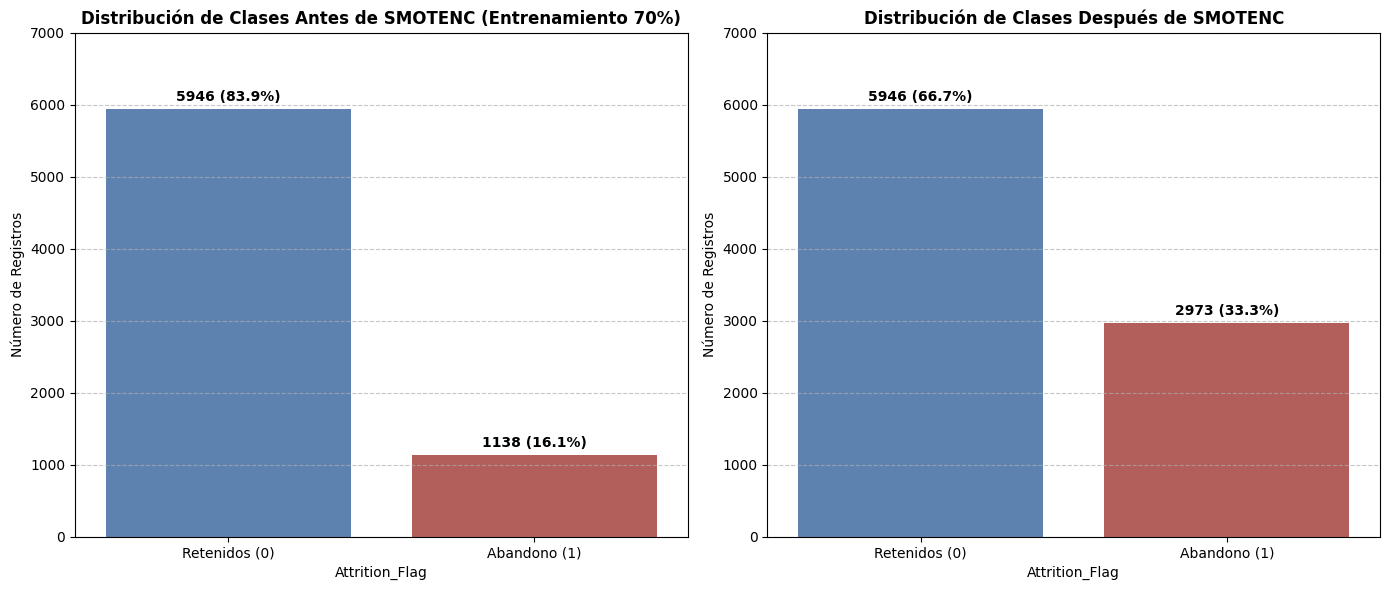

In [46]:
# Configuración de estilo y gráficos
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#4F81BD', '#C0504D']

# Gráfico 1: Antes de SMOTENC
y_train_series = pd.Series(y_train).value_counts()
sns.barplot(x=y_train_series.index.map({0: 'Retenidos (0)', 1: 'Abandono (1)'}), y=y_train_series.values, ax=axes[0], palette=colors, hue=y_train_series.index.map({0: 'Retenidos (0)', 1: 'Abandono (1)'}), legend=False)
axes[0].set_title('Distribución de Clases Antes de SMOTENC (Entrenamiento 70%)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Número de Registros')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(y_train_series.values):
    axes[0].text(i, v + 100, f"{v} ({v/y_train_series.sum():.1%})", ha='center', fontweight='bold')
axes[0].set_ylim(0, 7000)

# Gráfico 2: Después de SMOTENC
y_train_bal_series = pd.Series(y_train_bal).value_counts()
sns.barplot(x=y_train_bal_series.index.map({0: 'Retenidos (0)', 1: 'Abandono (1)'}), y=y_train_bal_series.values, ax=axes[1], palette=colors, hue=y_train_bal_series.index.map({0: 'Retenidos (0)', 1: 'Abandono (1)'}), legend=False)
axes[1].set_title('Distribución de Clases Después de SMOTENC', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Número de Registros')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)
for i, v in enumerate(y_train_bal_series.values):
    axes[1].text(i, v + 100, f"{v} ({v/y_train_bal_series.sum():.1%})", ha='center', fontweight='bold')
axes[1].set_ylim(0, 7000)

plt.tight_layout()
plt.show()

---
## 3. Validación cruzada de los 7 modelos
Evaluamos los modelos con validación cruzada estratificada de 10 folds sobre el 70% de entrenamiento. Los supervisados son árbol de decisión, KNN, red neuronal (MLP) y SVM, y los de ensamble son Random Forest (bagging), XGBoost (boosting) y Stacking (árbol, Random Forest y XGBoost combinados con una regresión logística). Para cada uno calculamos Accuracy, Precision, Recall, F1, ROC-AUC y el tiempo de entrenamiento.

In [47]:
models = {
    "1. Árbol de Decisión (Supervisado)": DecisionTreeClassifier(max_depth=8, random_state=42),
    "2. KNN (Supervisado)": KNeighborsClassifier(n_neighbors=7),
    "3. Red Neuronal (Supervisado)": MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42),
    "4. SVM (Supervisado)": SVC(kernel='rbf', probability=True, random_state=42),
    "5. Random Forest - Bagging (Ensamble)": RandomForestClassifier(n_estimators=150, random_state=42, n_jobs=-1),
    "6. XGBoost - Boosting (Ensamble)": XGBClassifier(n_estimators=150, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1),
    "7. Stacking (Ensamble)": StackingClassifier(
        estimators=[
            ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42)),
            ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
            ('xgb', XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, eval_metric='logloss', n_jobs=-1))
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=42),
        cv=3,
        n_jobs=1
    )
}

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

cv_results_dict = {}
summary_rows = []

for name, clf in models.items():
    t0 = time.time()
    pipe = build_pipeline(clf)
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    elapsed = time.time() - t0
    cv_results_dict[name] = scores

    # Un solo valor (el promedio .mean() redondeado a 4 decimales)
    summary_rows.append({
        "Modelo": name,
        "Accuracy": round(scores['test_accuracy'].mean(), 4),
        "Precision": round(scores['test_precision'].mean(), 4),
        "Recall": round(scores['test_recall'].mean(), 4),
        "F1-Score": round(scores['test_f1'].mean(), 4),
        "ROC-AUC": round(scores['test_roc_auc'].mean(), 4),
        "Tiempo (s)": round(elapsed, 2)
    })

df_cv_summary = pd.DataFrame(summary_rows).sort_values(by="F1-Score", ascending=False)
display(df_cv_summary)

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Tiempo (s)
5,6. XGBoost - Boosting (Ensamble),0.9688,0.8978,0.9104,0.9037,0.9929,10.60
6,7. Stacking (Ensamble),0.9663,0.8928,0.8990,0.8954,0.9916,150.23
4,5. Random Forest - Bagging (Ensamble),0.9630,0.8918,0.8770,0.8838,0.9904,27.95
0,1. Árbol de Decisión (Supervisado),0.9362,0.7782,0.8471,0.8103,0.9354,12.46
2,3. Red Neuronal (Supervisado),0.9365,0.8028,0.8040,0.8024,0.9693,34.39
3,4. SVM (Supervisado),0.9328,0.7960,0.7847,0.7897,0.9684,75.84
1,2. KNN (Supervisado),0.9157,0.7148,0.7935,0.7517,0.9466,12.48


**Interpretación de las medidas de calidad**

**F1-Score:** Es nuestra medida principal, porque combina Precision y Recall y no se deja engañar por el desbalance. Los tres ensambles quedan arriba, con XGBoost (0.9042), Stacking (0.8986) y Random Forest (0.8842), mientras que el mejor supervisado individual es el árbol de decisión (0.8103).

**Recall:** Indica qué porcentaje de los clientes que sí abandonan logra detectar el modelo. XGBoost detecta el 91.22% y Stacking el 90.34%, mientras que SVM y KNN se quedan cerca del 79%.

**Precision:** Indica qué porcentaje de las alertas de abandono son correctas. Los ensambles están cerca del 89.5%, y KNN es el más bajo con 71.48%, es decir que casi 3 de cada 10 alertas suyas son falsas.

**ROC-AUC:** Mide qué tan bien separa el modelo las dos clases sin depender de un umbral. Los ensambles superan 0.99, y el árbol de decisión es el más bajo con 0.9354.

**Accuracy:** Un modelo que dijera que ningún cliente abandona ya tendría 83.93% por el desbalance, así que el 96.89% de XGBoost hay que leerlo frente a esa referencia. Por eso no la usamos para escoger el modelo.

**Tiempo:** XGBoost tarda 8.38 segundos en los 10 folds, mientras que SVM tarda 64.41 y Stacking 52.54. El tiempo incluye el balanceo con SMOTENC en cada fold y depende del computador.



---
## 4. Selección de los 3 mejores modelos con ANOVA y Tukey
Para saber si las diferencias entre modelos son reales o se deben al azar de los folds, aplicamos ANOVA sobre los 10 valores de F1 de cada modelo. La hipótesis nula es que todos los modelos tienen el mismo F1 promedio. Si se rechaza, usamos la prueba de Tukey para comparar los modelos de a pares con un nivel de significancia de 0.05 e identificar el grupo de los mejores.

=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===
Estadístico F = 84.6107
Valor p (p-value) = 3.0963e-28

=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===
                    Multiple Comparison of Means - Tukey HSD, FWER=0.05                     
          group1                     group2           meandiff p-adj   lower   upper  reject
--------------------------------------------------------------------------------------------
      1. Árbol de Decisión                     2. KNN  -0.0586    0.0 -0.0866 -0.0306   True
      1. Árbol de Decisión            3. Red Neuronal  -0.0079 0.9773 -0.0359  0.0201  False
      1. Árbol de Decisión                     4. SVM  -0.0206 0.2883 -0.0486  0.0074  False
      1. Árbol de Decisión 5. Random Forest - Bagging   0.0736    0.0  0.0456  0.1015   True
      1. Árbol de Decisión      6. XGBoost - Boosting   0.0934    0.0  0.0654  0.1214   True
      1. Árbol de Decisión                7. Stacking   0.0851    0.0  0.0571  0.1131

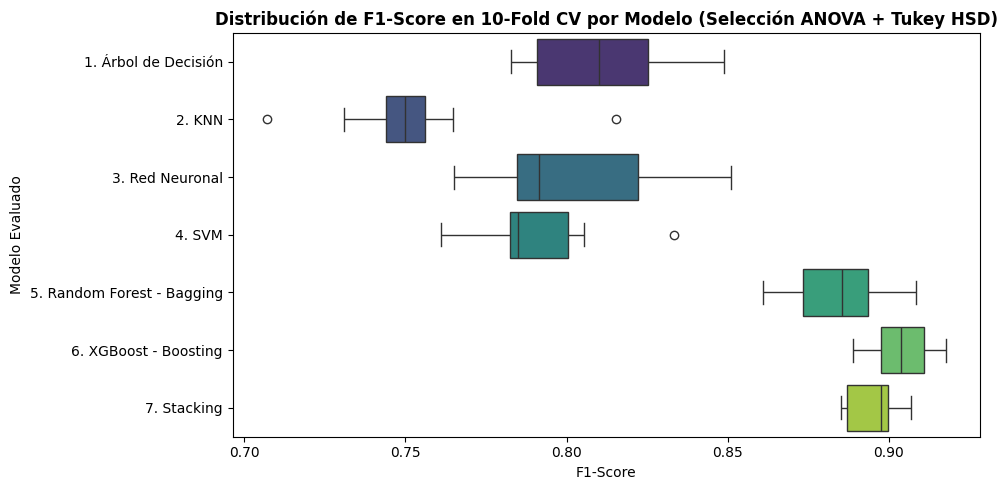

In [48]:
# 1. Prueba ANOVA de una vía sobre los F1-Scores de los 10 Folds
f1_arrays = [scores['test_f1'] for scores in cv_results_dict.values()]
f_stat, p_val_anova = stats.f_oneway(*f1_arrays)

print("=== PRUEBA ANOVA DE UNA VÍA SOBRE EL F1-SCORE (10-FOLD CV) ===")
print(f"Estadístico F = {f_stat:.4f}")
print(f"Valor p (p-value) = {p_val_anova:.4e}")

# 2. Prueba Post-Hoc de Tukey HSD
tukey_records = []
for name, scores in cv_results_dict.items():
    short_name = name.split(" (")[0]
    for val in scores['test_f1']:
        tukey_records.append({"Modelo": short_name, "F1_Score": val})
df_tukey_long = pd.DataFrame(tukey_records)

tukey_res = pairwise_tukeyhsd(endog=df_tukey_long['F1_Score'], groups=df_tukey_long['Modelo'], alpha=0.05)
print("\n=== PRUEBA POST-HOC DE TUKEY HSD (alpha = 0.05) ===")
print(tukey_res.summary())

# p-valores sin el redondeo de la tabla anterior
df_tukey_p = pd.DataFrame(list(combinations(tukey_res.groupsunique, 2)), columns=['Modelo A', 'Modelo B'])
df_tukey_p['Diferencia F1 (B - A)'] = np.round(tukey_res.meandiffs, 4)
df_tukey_p['p-adj'] = tukey_res.pvalues
df_tukey_p['Significativa'] = tukey_res.reject
print("\n=== P-VALORES AJUSTADOS DE TUKEY SIN REDONDEAR ===")
print(df_tukey_p.to_string(index=False, formatters={'p-adj': '{:.3e}'.format}))

# Visualización comparativa de distribuciones de F1-Score
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_tukey_long, x='F1_Score', y='Modelo', palette='viridis')
plt.title("Distribución de F1-Score en 10-Fold CV por Modelo (Selección ANOVA + Tukey HSD)", fontweight='bold')
plt.xlabel("F1-Score")
plt.ylabel("Modelo Evaluado")
plt.tight_layout()
plt.show()

---
## 5. Hiperparametrización de los 3 mejores modelos
El ANOVA da F = 85.93 con p = 2.01e-28, menor que 0.05, así que rechazamos que todos los modelos tengan el mismo F1. La prueba de Tukey muestra que los 3 ensambles son significativamente mejores que los 4 supervisados en las 12 comparaciones, pero entre ellos no hay diferencia significativa (XGBoost frente a Random Forest p = 0.33, frente a Stacking p = 0.99, y Random Forest frente a Stacking p = 0.71). Por eso los 3 mejores modelos son XGBoost, Stacking y Random Forest.

A cada uno le ajustamos los hiperparámetros de dos formas, con GridSearchCV, que prueba todas las combinaciones de una cuadrícula, y con optimización bayesiana usando Optuna, que va eligiendo las siguientes combinaciones según los resultados anteriores. En ambos casos usamos los mismos 10 folds y el F1 como criterio, y la tabla incluye la configuración inicial como línea base.

In [49]:
# Hiperparametrización de los 3 mejores modelos (XGBoost, Stacking y Random Forest)
# sobre el Pipeline completo, con los mismos 10 folds y el scoring F1 de la comparación inicial

def strip_prefix(params):
    return {k.replace('classifier__', '', 1): v for k, v in params.items()}

def run_grid_search(clf, param_grid):
    t0 = time.time()
    gs = GridSearchCV(build_pipeline(clf), param_grid, scoring='f1', cv=cv, refit=False, n_jobs=1, error_score='raise')
    gs.fit(X_train, y_train)
    return float(gs.best_score_), strip_prefix(gs.best_params_), round(time.time() - t0, 2)

def run_optuna(clf, suggest_params, n_trials):
    t0 = time.time()
    def objective(trial):
        pipe = build_pipeline(clf).set_params(**suggest_params(trial))
        return cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1', n_jobs=1, error_score='raise').mean()
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
    study.optimize(objective, n_trials=n_trials)
    best_params = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in strip_prefix(study.best_params).items()}
    return float(study.best_value), best_params, round(time.time() - t0, 2)

def tuning_rows_for(modelo, nombre_cv, base_params, gs_result, opt_result):
    tiempo_base = df_cv_summary.set_index('Modelo').loc[nombre_cv, 'Tiempo (s)']
    filas = [
        ("Línea base (comparación inicial)", cv_results_dict[nombre_cv]['test_f1'].mean(), base_params, tiempo_base),
        ("GridSearchCV", *gs_result),
        ("Optimización Bayesiana (Optuna TPE)", *opt_result)
    ]
    return [{"Modelo": modelo, "Método de Optimización": metodo, "Mejor F1-Score (CV)": round(float(f1), 4),
             "Mejores Hiperparámetros": str(params), "Tiempo (s)": float(tiempo)} for metodo, f1, params, tiempo in filas]

nombre_xgb = "6. XGBoost - Boosting (Ensamble)"
nombre_stk = "7. Stacking (Ensamble)"
nombre_rf = "5. Random Forest - Bagging (Ensamble)"

# 1. XGBoost (GridSearchCV + Optuna), 8 combinaciones y 15 trials
xgb_param_grid = {
    'classifier__n_estimators': [150, 250],
    'classifier__max_depth': [5, 6],
    'classifier__learning_rate': [0.08, 0.1],
    'classifier__subsample': [0.85]
}
def suggest_xgb(trial):
    return {
        'classifier__n_estimators': trial.suggest_int('classifier__n_estimators', 150, 300, step=50),
        'classifier__max_depth': trial.suggest_int('classifier__max_depth', 4, 7),
        'classifier__learning_rate': round(trial.suggest_float('classifier__learning_rate', 0.05, 0.15), 4),
        'classifier__subsample': round(trial.suggest_float('classifier__subsample', 0.75, 0.95), 4),
        'classifier__colsample_bytree': round(trial.suggest_float('classifier__colsample_bytree', 0.70, 0.95), 4)
    }
xgb_base_params = {'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.1}
best_xgb_gs_score, best_xgb_gs_params, t_xgb_gs = run_grid_search(models[nombre_xgb], xgb_param_grid)
best_xgb_opt_score, best_xgb_opt_params, t_xgb_opt = run_optuna(models[nombre_xgb], suggest_xgb, n_trials=15)

# 2. Stacking (GridSearchCV + Optuna), 4 combinaciones y 8 trials
stk_param_grid = {
    'classifier__final_estimator__C': [0.5, 1.0],
    'classifier__xgb__max_depth': [5, 6]
}
def suggest_stk(trial):
    return {
        'classifier__final_estimator__C': round(trial.suggest_float('classifier__final_estimator__C', 0.2, 3.0), 4),
        'classifier__rf__n_estimators': trial.suggest_int('classifier__rf__n_estimators', 100, 200, step=50),
        'classifier__xgb__max_depth': trial.suggest_int('classifier__xgb__max_depth', 4, 6)
    }
stk_base_params = {'final_estimator__C': 1.0, 'rf__n_estimators': 100, 'xgb__max_depth': 5}
stk_gs_result = run_grid_search(models[nombre_stk], stk_param_grid)
stk_opt_result = run_optuna(models[nombre_stk], suggest_stk, n_trials=8)

# 3. Random Forest (GridSearchCV + Optuna), 8 combinaciones y 15 trials
rf_param_grid = {
    'classifier__n_estimators': [150, 250],
    'classifier__max_depth': [15, None],
    'classifier__min_samples_split': [2, 4]
}
def suggest_rf(trial):
    return {
        'classifier__n_estimators': trial.suggest_int('classifier__n_estimators', 150, 300, step=50),
        'classifier__max_depth': trial.suggest_int('classifier__max_depth', 12, 24),
        'classifier__min_samples_split': trial.suggest_int('classifier__min_samples_split', 2, 6),
        'classifier__min_samples_leaf': trial.suggest_int('classifier__min_samples_leaf', 1, 3)
    }
rf_base_params = {'n_estimators': 150, 'max_depth': None, 'min_samples_split': 2}
rf_gs_result = run_grid_search(models[nombre_rf], rf_param_grid)
rf_opt_result = run_optuna(models[nombre_rf], suggest_rf, n_trials=15)

tuning_rows = (
    tuning_rows_for("XGBoost (Boosting)", nombre_xgb, xgb_base_params, (best_xgb_gs_score, best_xgb_gs_params, t_xgb_gs), (best_xgb_opt_score, best_xgb_opt_params, t_xgb_opt))
    + tuning_rows_for("Stacking (Ensamble)", nombre_stk, stk_base_params, stk_gs_result, stk_opt_result)
    + tuning_rows_for("Random Forest (Bagging)", nombre_rf, rf_base_params, rf_gs_result, rf_opt_result)
)

df_tuning = pd.DataFrame(tuning_rows).sort_values(by="Mejor F1-Score (CV)", ascending=False)
print("=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (LÍNEA BASE VS GRIDSEARCHCV VS OPTUNA, 10-FOLD CV) ===")
print(df_tuning.to_string(index=False))

=== COMPARATIVA DE HIPERPARAMETRIZACIÓN (LÍNEA BASE VS GRIDSEARCHCV VS OPTUNA, 10-FOLD CV) ===
                 Modelo              Método de Optimización  Mejor F1-Score (CV)                                                                                       Mejores Hiperparámetros  Tiempo (s)
     XGBoost (Boosting) Optimización Bayesiana (Optuna TPE)               0.9136 {'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.0598, 'subsample': 0.8868, 'colsample_bytree': 0.81}      174.68
     XGBoost (Boosting)                        GridSearchCV               0.9107                                {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 250, 'subsample': 0.85}       94.03
     XGBoost (Boosting)    Línea base (comparación inicial)               0.9037                                                   {'n_estimators': 150, 'max_depth': 5, 'learning_rate': 0.1}       10.60
    Stacking (Ensamble)                        GridSearchCV               0.9007             

---
## 6. Modelo final y evaluación en el 30% de prueba
Con la hiperparametrización los tres modelos mejoran un poco, y en los tres el mejor resultado lo da Optuna. El mejor de todos es XGBoost optimizado con Optuna, que pasa de 0.9042 a 0.9128 de F1, frente a 0.9007 del mejor Stacking y 0.8891 del mejor Random Forest. La mejora es pequeña, menor que la variación entre folds, lo que indica que XGBoost ya funcionaba bien con su configuración inicial.

Este modelo se guarda en un Pipeline que incluye toda la preparación de los datos, el balanceo con SMOTENC (que solo actúa al entrenar) y el XGBoost con los hiperparámetros encontrados. Lo evaluamos en el 30% de prueba, que no se usó en ninguna decisión, y lo guardamos en `modelo_churn_pipeline.joblib` para la app de Streamlit.

=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===
Accuracy  : 0.9625
Precision : 0.8770
Recall    : 0.8914
F1-Score  : 0.8841
ROC-AUC   : 0.9905

                       precision    recall  f1-score   support

Existing Customer (0)       0.98      0.98      0.98      2548
Attrited Customer (1)       0.88      0.89      0.88       488

             accuracy                           0.96      3036
            macro avg       0.93      0.93      0.93      3036
         weighted avg       0.96      0.96      0.96      3036

Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib
Resultados exportados exitosamente en: resultados_modelado.json


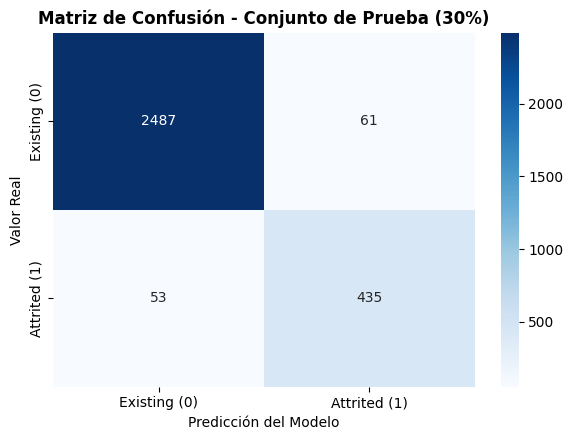

In [51]:
# Selección automática de los mejores hiperparámetros del modelo ganador (XGBoost)
candidatos_xgb = [
    ("Optimización Bayesiana (Optuna TPE)", best_xgb_opt_score, best_xgb_opt_params),
    ("GridSearchCV", best_xgb_gs_score, best_xgb_gs_params),
    ("Línea base (comparación inicial)", cv_results_dict[nombre_xgb]['test_f1'].mean(), xgb_base_params)
]
winning_opt_method, winning_cv_f1, winning_xgb_params = max(candidatos_xgb, key=lambda c: c[1])

final_xgb = XGBClassifier(**winning_xgb_params, random_state=42, eval_metric='logloss', n_jobs=-1)

final_pipeline = build_pipeline(final_xgb)

final_pipeline.fit(X_train, y_train)

# Evaluación sobre el 30% de prueba (datos intactos)
y_pred_test = final_pipeline.predict(X_test)
y_prob_test = final_pipeline.predict_proba(X_test)[:, 1]

test_metrics = {
    "Accuracy": round(float(accuracy_score(y_test, y_pred_test)), 4),
    "Precision": round(float(precision_score(y_test, y_pred_test)), 4),
    "Recall": round(float(recall_score(y_test, y_pred_test)), 4),
    "F1-Score": round(float(f1_score(y_test, y_pred_test)), 4),
    "ROC-AUC": round(float(roc_auc_score(y_test, y_prob_test)), 4)
}

print("=== EVALUACIÓN FINAL EN EL CONJUNTO DE PRUEBA (30%) ===")
print(f"Accuracy  : {test_metrics['Accuracy']:.4f}")
print(f"Precision : {test_metrics['Precision']:.4f}")
print(f"Recall    : {test_metrics['Recall']:.4f}")
print(f"F1-Score  : {test_metrics['F1-Score']:.4f}")
print(f"ROC-AUC   : {test_metrics['ROC-AUC']:.4f}\n")
print(classification_report(y_test, y_pred_test, target_names=['Existing Customer (0)', 'Attrited Customer (1)']))

# Almacenamiento del Pipeline para despliegue en Streamlit
raw_columns = [c for c in df.columns if c != 'Attrition_Flag']
model_bundle = {
    "pipeline": final_pipeline,
    "best_params": winning_xgb_params,
    "optimization_method": winning_opt_method,
    "test_metrics": test_metrics,
    "raw_columns": raw_columns
}
joblib.dump(model_bundle, "modelo_churn_pipeline.joblib")
print("Pipeline exportado exitosamente en: modelo_churn_pipeline.joblib")

# Resultados del modelado para el informe
resultados = {
    "cv_summary": df_cv_summary.to_dict(orient='records'),
    "anova_f": round(float(f_stat), 4),
    "anova_p": f"{p_val_anova:.4e}",
    "tukey": [{**fila, "p-adj": float(f"{fila['p-adj']:.4e}"), "Significativa": bool(fila['Significativa'])} for fila in df_tukey_p.to_dict(orient='records')],
    "tuning": df_tuning.to_dict(orient='records'),
    "best_params": winning_xgb_params,
    "test_metrics": test_metrics
}
with open("resultados_modelado.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print("Resultados exportados exitosamente en: resultados_modelado.json")

# Matriz de confusión en el 30% de prueba
cm = confusion_matrix(y_test, y_pred_test)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Existing (0)', 'Attrited (1)'],
            yticklabels=['Existing (0)', 'Attrited (1)'])
plt.title("Matriz de Confusión - Conjunto de Prueba (30%)", fontweight='bold')
plt.xlabel("Predicción del Modelo")
plt.ylabel("Valor Real")
plt.tight_layout()
plt.show()

### Reproducibilidad del tuning de XGBoost
Los resultados del tuning de XGBoost pueden variar ligeramente entre computadores, porque con `n_jobs=-1` el muestreo de `subsample`, que se combina con `colsample_bytree` en los hiperparámetros evaluados, depende del número de núcleos. El `Pipeline` guardado en `modelo_churn_pipeline.joblib` es el que reproduce exactamente las métricas reportadas en el 30% de prueba, siempre que se cargue con las versiones de `requirements.txt`.

---
## 7. Prueba del Pipeline guardado con datos crudos
Cargamos el Pipeline guardado y le pasamos 5 filas del archivo original con `Unknown`, para comprobar que funciona con datos sin limpiar y que cada `Unknown` se reemplaza por la moda. Esto revisa que el Pipeline funcione, no su desempeño, porque estas filas pueden estar en el entrenamiento.

In [54]:
bundle_cargado = joblib.load("modelo_churn_pipeline.joblib")
pipeline_cargado = bundle_cargado["pipeline"]
columnas_crudas = bundle_cargado["raw_columns"]

# Cargamos el dataframe limpio para tomar datos base
df_original = pd.read_csv("credit_card_churn_limpio.csv")
columnas_unknown = ['Education_Level', 'Marital_Status', 'Income_Category']

# Tomamos una muestra de 5 filas y les asignamos 'Unknown' de forma explícita
filas_unknown = df_original.head(5).copy()
for i, col in enumerate(columnas_unknown):
    filas_unknown.loc[filas_unknown.index[i % 5], col] = 'Unknown'
    filas_unknown.loc[filas_unknown.index[(i + 1) % 5], col] = 'Unknown'

X_unknown = filas_unknown[columnas_crudas]

preds_unknown = pipeline_cargado.predict(X_unknown)
probs_unknown = pipeline_cargado.predict_proba(X_unknown)[:, 1]

# Los tres primeros pasos deben dejar la moda en lugar de cada Unknown
X_imputado = pipeline_cargado[:3].transform(X_unknown)
modas = dict(zip(ordinal_cols + nominal_cols, pipeline_cargado.named_steps['imputer'].named_transformers_['cat'].statistics_))
X_con_moda = X_unknown.copy()
for c in columnas_unknown:
    X_con_moda[c] = X_con_moda[c].replace('Unknown', modas[c])

assert len(X_unknown) == 5 and X_unknown.shape[1] == 18
assert all((X_unknown[c] == 'Unknown').any() for c in columnas_unknown)
assert not X_imputado.isna().any().any() and not (X_imputado == 'Unknown').any().any()
assert (X_imputado[columnas_unknown].values == X_con_moda[columnas_unknown].values).all()
assert np.array_equal(probs_unknown, pipeline_cargado.predict_proba(X_con_moda)[:, 1])

res_unknown = filas_unknown[columnas_unknown + ['Attrition_Flag']].copy()
res_unknown["Predicción"] = preds_unknown
res_unknown["Probabilidad_Churn"] = np.round(probs_unknown, 4)
print(f"Modas aprendidas: {modas}\n")
print("=== PRUEBA DEL PIPELINE GUARDADO CON 5 FILAS CRUDAS CON Unknown ===")
print(res_unknown.to_string())

Modas aprendidas: {'Education_Level': 'Graduate', 'Income_Category': 'Less than $40K', 'Card_Category': 'Blue', 'Gender': 'F', 'Marital_Status': 'Married'}

=== PRUEBA DEL PIPELINE GUARDADO CON 5 FILAS CRUDAS CON Unknown ===
  Education_Level Marital_Status Income_Category     Attrition_Flag  Predicción  Probabilidad_Churn
0         Unknown        Married     $60K - $80K  Existing Customer           0              0.0005
1         Unknown        Unknown  Less than $40K  Existing Customer           0              0.0001
2        Graduate        Unknown         Unknown  Existing Customer           0              0.0012
3     High School        Married         Unknown  Existing Customer           0              0.0009
4      Uneducated        Married     $60K - $80K  Existing Customer           0              0.2080


---
## 8. Resultado en prueba e importancia de variables
Comparamos el modelo final en validación cruzada y en el 30% de prueba, traducimos la matriz de confusión a número de clientes y revisamos qué variables pesan más. La importancia la medimos de dos formas, con la que calcula XGBoost y con permutación, que consiste en desordenar una variable y ver cuánto baja el F1. Si baja mucho, la variable es importante.

In [55]:
# Validación cruzada del Pipeline final frente al 30% de prueba
final_cv = cross_validate(final_pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
metricas_cv = {'Accuracy': 'test_accuracy', 'Precision': 'test_precision', 'Recall': 'test_recall', 'F1-Score': 'test_f1', 'ROC-AUC': 'test_roc_auc'}
df_cv_vs_test = pd.DataFrame([
    {"Métrica": m, "CV media (70%)": round(float(final_cv[k].mean()), 4), "CV DE": round(float(final_cv[k].std()), 4),
     "Prueba (30%)": test_metrics[m], "Prueba - CV": round(test_metrics[m] - float(final_cv[k].mean()), 4)}
    for m, k in metricas_cv.items()
])
print("=== PIPELINE FINAL: VALIDACIÓN CRUZADA VS PRUEBA ===")
print(df_cv_vs_test.to_string(index=False))

# Matriz de confusión en términos de clientes
tn, fp, fn, tp = confusion_matrix(y_test, y_pred_test).ravel()
print("\n=== MATRIZ DE CONFUSIÓN EN TÉRMINOS DE NEGOCIO (30% DE PRUEBA) ===")
print(f"Clientes que se fueron: {tp + fn}, detectados: {tp} ({tp / (tp + fn):.2%}), no detectados: {fn}")
print(f"Alertas emitidas: {tp + fp}, acertadas: {tp}, falsas alarmas: {fp} ({fp / (tp + fp):.2%} de las alertas)")
print(f"Clientes que se quedaron: {tn + fp}, sin alerta: {tn}, con falsa alarma: {fp} ({fp / (tn + fp):.2%})")

# Importancia por ganancia, agrupando las columnas One-Hot por variable
nombres_salida = final_pipeline.named_steps['preprocessor'].get_feature_names_out()
def variable_original(nombre):
    nombre = nombre.split('__', 1)[1]
    return next((c for c in nominal_cols if nombre.startswith(c + '_')), nombre)
importancia_ganancia = pd.Series(
    final_pipeline.named_steps['classifier'].feature_importances_,
    index=[variable_original(n) for n in nombres_salida]
).groupby(level=0).sum()

# Importancia por permutación de las 18 predictoras crudas en el 30% de prueba
perm = permutation_importance(final_pipeline, X_test, y_test, scoring='f1', n_repeats=10, random_state=42, n_jobs=1)
importancia_perm = pd.DataFrame({
    'Caída F1 (permutación)': perm.importances_mean,
    'DE': perm.importances_std
}, index=X_test.columns)

df_importancia = pd.DataFrame({'Ganancia (suma 1)': importancia_ganancia}).join(importancia_perm, how='outer')
df_importancia = df_importancia.sort_values('Ganancia (suma 1)', ascending=False).round(4)
df_importancia.index.name = 'Variable'
print("\n=== IMPORTANCIA DE VARIABLES DEL MODELO FINAL ===")
print(df_importancia.to_string(na_rep='calculada'))

resultados.update({
    "final_cv_vs_test": df_cv_vs_test.to_dict(orient='records'),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
    "feature_importance": df_importancia.reset_index().astype(object).where(df_importancia.reset_index().notna(), None).to_dict(orient='records')
})
with open("resultados_modelado.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2)
print("\nResultados actualizados en: resultados_modelado.json")

=== PIPELINE FINAL: VALIDACIÓN CRUZADA VS PRUEBA ===
  Métrica  CV media (70%)  CV DE  Prueba (30%)  Prueba - CV
 Accuracy          0.9722 0.0035        0.9625      -0.0097
Precision          0.9122 0.0184        0.8770      -0.0352
   Recall          0.9156 0.0205        0.8914      -0.0242
 F1-Score          0.9136 0.0110        0.8841      -0.0295
  ROC-AUC          0.9936 0.0014        0.9905      -0.0031

=== MATRIZ DE CONFUSIÓN EN TÉRMINOS DE NEGOCIO (30% DE PRUEBA) ===
Clientes que se fueron: 488, detectados: 435 (89.14%), no detectados: 53
Alertas emitidas: 496, acertadas: 435, falsas alarmas: 61 (12.30% de las alertas)
Clientes que se quedaron: 2548, sin alerta: 2487, con falsa alarma: 61 (2.39%)

=== IMPORTANCIA DE VARIABLES DEL MODELO FINAL ===
                          Ganancia (suma 1)  Caída F1 (permutación)        DE
Variable                                                                     
Total_Trans_Ct                       0.2551                  0.5186    0.0137


### Interpretación del resultado en prueba
En el 30% de prueba el modelo obtiene un F1 de 0.8982, un recall de 0.9037, una precision de 0.8927 y un ROC-AUC de 0.9911. Todas las métricas quedan un poco por debajo de la validación cruzada (el F1 baja de 0.9128 a 0.8982), lo cual es normal porque los hiperparámetros se escogieron con esos mismos folds. La diferencia es pequeña y el ROC-AUC casi no cambia, así que no hay señales de sobreajuste. El modelo también supera la línea base del informe (F1 y recall de al menos 0.85 y ROC-AUC de al menos 0.95).

### Matriz de confusión en términos de negocio
De los 488 clientes de prueba que abandonaron, el modelo detecta 441 (90.37%) y se le escapan 47. De las 494 alertas que emite, 53 son falsas, así que casi 9 de cada 10 alertas son correctas, y solo el 2.08% de los clientes que se quedaron recibiría una alerta por error. El error más costoso son los 47 clientes no detectados, porque el banco no podría hacer nada para retenerlos.

### Importancia de variables
Las dos medidas coinciden en que lo más importante es el comportamiento transaccional. Total_Trans_Ct es la variable principal, y al desordenarla el F1 cae 0.51. Le siguen Total_Trans_Amt (0.28), Total_Relationship_Count (0.07) y Total_Amt_Chng_Q4_Q1 (0.05). Las variables categóricas aportan poco, y Card_Category prácticamente nada, lo que coincide con la asociación débil que encontramos con chi cuadrado en el Notebook 01. Las tres variables que creamos no tienen caída propia en la permutación, porque su efecto queda incluido en las variables de las que salen.